In [17]:
import pandas as pd
import numpy as np
import re
from scipy import stats
import matplotlib.pyplot as plt

In [3]:
# Load dataset
bgg_dataset = pd.read_csv("bgg_dataset.csv", sep=';')
bgg_dataset.head()

,ID,Name,Year Published,Min Players,Max Players,Play Time,Min Age,Users Rated,Rating Average,BGG Rank,Complexity Average,Owned Users,Mechanics,Domains
0,174430.0,Gloomhaven,2017.0,1,4,120,14,42055,"8,79",1,"3,86",68323.0,"Action Queue, Action Retrieval, Campaign / Bat...","Strategy Games, Thematic Games"
1,161936.0,Pandemic Legacy: Season 1,2015.0,2,4,60,13,41643,"8,61",2,"2,84",65294.0,"Action Points, Cooperative Game, Hand Manageme...","Strategy Games, Thematic Games"
2,224517.0,Brass: Birmingham,2018.0,2,4,120,14,19217,"8,66",3,"3,91",28785.0,"Hand Management, Income, Loans, Market, Networ...",Strategy Games
3,167791.0,Terraforming Mars,2016.0,1,5,120,12,64864,"8,43",4,"3,24",87099.0,"Card Drafting, Drafting, End Game Bonuses, Han...",Strategy Games
4,233078.0,Twilight Imperium: Fourth Edition,2017.0,3,6,480,14,13468,"8,70",5,"4,22",16831.0,"Action Drafting, Area Majority / Influence, Ar...","Strategy Games, Thematic Games"


## convert currencies to USD

In [4]:
df = pd.read_csv('products_with_edition.csv')
df = df.drop(columns=['price_in_usd'])
df

def convert_to_usd(amount, currency, rates):
    currency = str(currency).upper()
    if currency not in rates or pd.isna(amount):
        return None
    return round(float(amount) * rates[currency], 2)

rates = {
    'USD': 1.0,
    'EUR': 1.10,
    'GBP': 1.30,
    'AUD': 0.65,
    'CAD': 0.75,
    'CHF': 1.05,
    'SGD': 0.73,
    'SEK': 0.10,
    'PLN': 0.24,
    'HUF': 0.0027,
    'MXN': 0.057,
    'NZD': 0.60,
    'JPY': 0.0073,
    'CNY': 0.14,
    'BRL': 0.19,
    'CZK': 0.042,
    'MYR': 0.21,
}

df['currency'] = df['currency'].str.upper()

df['price'] = df['price'] * df['currency'].map(rates)

df['currency'] = 'USD'

df['price'] = df['price'].round(2)
df

,productid,objecttype,objectid,producthref,price,currency,currencystring,currencysymbol,condition,prettycondition,...,quantity,userId,username,user_country,user_city,version_name,version_href,game_name,game_href,linkeduserGeekMarket
0,3870857,thing,1,/market/product/3870857,30.00,USD,U.S. dollars,$,likenew,Like New,...,1,2954044,LeBao,United States,Tallahassee,Die Macher (Multilingual edition 2006),/boardgameversion/24534/multilingual-edition-2006,Die Macher,/boardgame/1/die-macher,NaN
1,3866054,thing,1,/market/product/3866054,180.00,USD,U.S. dollars,$,new,New,...,1,3677448,CarsonChandler,United States,Christiansburg,Die Macher (Spielworxx English/German edition),/boardgameversion/455802/spielworxx-englishger...,Die Macher,/boardgame/1/die-macher,NaN
2,3854476,thing,1,/market/product/3854476,41.99,USD,U.S. dollars,$,likenew,Like New,...,1,215794,Eric Engelmann,United States,Rockville,Die Macher (Spielworxx English/German edition),/boardgameversion/455802/spielworxx-englishger...,Die Macher,/boardgame/1/die-macher,NaN
3,3853310,thing,1,/market/product/3853310,66.00,USD,Euros,€,new,New,...,1,1613268,JillySilly,Belgium,NaN,Die Macher (Spielworxx English/German edition),/boardgameversion/455802/spielworxx-englishger...,Die Macher,/boardgame/1/die-macher,NaN
4,3845442,thing,1,/market/product/3845442,50.00,USD,U.S. dollars,$,verygood,Very Good,...,1,38240,caesarmom,United States,Lorton,Die Macher (German-only second edition),/boardgameversion/24939/german-only-second-edi...,Die Macher,/boardgame/1/die-macher,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
178007,2589638,thing,99992,/market/product/2589638,11.00,USD,Euros,€,new,New,...,1,9646,Edgar Gallego,Spain,Sarriguren,NaN,NaN,Kill Shot: The Counter-Terrorism Party Game,/boardgame/99992/kill-shot-the-counter-terrori...,NaN
178008,2545360,thing,99992,/market/product/2545360,5.00,USD,U.S. dollars,$,likenew,Like New,...,1,840122,ohkoolnerd,United States,Struthers,Kill Shot: The Counter-Terrorism Party Game (E...,/boardgameversion/101405/english-edition,Kill Shot: The Counter-Terrorism Party Game,/boardgame/99992/kill-shot-the-counter-terrori...,NaN
178009,2136397,thing,99992,/market/product/2136397,8.00,USD,U.S. dollars,$,likenew,Like New,...,1,102667,Strom40,United States,Ypsilanti,Kill Shot: The Counter-Terrorism Party Game (E...,/boardgameversion/101405/english-edition,Kill Shot: The Counter-Terrorism Party Game,/boardgame/99992/kill-shot-the-counter-terrori...,NaN
178010,1372069,thing,99992,/market/product/1372069,13.00,USD,U.S. dollars,$,new,New,...,1,681464,biphead1,United States,Queens,NaN,NaN,Kill Shot: The Counter-Terrorism Party Game,/boardgame/99992/kill-shot-the-counter-terrori...,NaN


In [5]:
import pandas as pd

# --- 1. Keep only the required columns ---
cols_to_keep = [
    "objectid",
    "price",
    "version_name",
    "condition"
]

products_clean = df.loc[:, cols_to_keep].copy()

# --- 2. Drop rows with missing IDs or prices ---
products_clean = products_clean.dropna(subset=["objectid", "price"])

# --- 3. Convert data types safely ---
products_clean["objectid"] = pd.to_numeric(
    products_clean["objectid"], errors="coerce"
)
products_clean["price"] = pd.to_numeric(
    products_clean["price"], errors="coerce"
)

# Drop rows that failed conversion
products_clean = products_clean.dropna(subset=["objectid", "price"])
products_clean["objectid"] = products_clean["objectid"].astype(int)

# --- 4. Clean and standardize condition ---
products_clean["condition"] = (
    products_clean["condition"]
    .astype(str)
    .str.lower()
    .str.strip()
)

# --- 5. Keep ONLY 'new' condition ---
products_clean = products_clean[products_clean["condition"] == "new"].copy()

# --- 6. Clean version names ---
products_clean["version_name"] = (
    products_clean["version_name"]
    .astype(str)
    .str.strip()
)

# --- 7. Remove exact duplicate rows ---
products_clean = products_clean.drop_duplicates(
    subset=["objectid", "version_name", "condition", "price"]
)

# --- 8. Average duplicated game versions ---
products_clean_avg = products_clean.groupby(
    ["objectid", "version_name", "condition"], as_index=False
)["price"].mean()

# ✅ Final verified clean dataset
products_clean_avg.head()


,objectid,version_name,condition,price
0,1,Die Macher (German-only second edition),new,73.630000
1,1,Die Macher (Multilingual edition 2006),new,44.500000
2,1,Die Macher (Spanish edition),new,46.200000
3,1,Die Macher (Spielworxx English/German edition ...,new,71.500000
4,1,Die Macher (Spielworxx English/German edition),new,121.998333


In [6]:
# 1️⃣ Check dataset shape
print("Dataset shape:", products_clean_avg.shape)

# 2️⃣ Check for missing values
print("\nMissing values per column:")
print(products_clean_avg.isna().sum())

# 3️⃣ Check that ONLY 'new' condition exists
print("\nUnique conditions:")
print(products_clean_avg["condition"].unique())

# 4️⃣ Check data types
print("\nData types:")
print(products_clean_avg.dtypes)

# 5️⃣ Check for duplicate (objectid + version_name)
duplicates = products_clean_avg.duplicated(
    subset=["objectid", "version_name"]
).sum()

print("\nDuplicate (s duplicated game+version rows:", duplicates)

# 6️⃣ Check for invalid prices (zero or negative)
invalid_prices = (products_clean_avg["price"] <= 0).sum()
print("\nInvalid prices (<=0):", invalid_prices)

# 7️⃣ Price summary (sanity check)
print("\nPrice distribution:")
print(products_clean_avg["price"].describe())

# 8️⃣ Sample random rows for manual verification
print("\nRandom sample:")
products_clean_avg.sample(5)


Dataset shape: (25352, 4)

Missing values per column:
objectid        0
version_name    0
condition       0
price           0
dtype: int64

Unique conditions:
['new']

Data types:
objectid          int64
version_name     object
condition        object
price           float64
dtype: object

Duplicate (s duplicated game+version rows: 0

Invalid prices (<=0): 0

Price distribution:
count    25352.000000
mean        53.322392
std        565.629580
min          0.750000
25%         18.150000
50%         30.000000
75%         52.198500
max      80246.400000
Name: price, dtype: float64

Random sample:


,objectid,version_name,condition,price
19771,230650,nan,new,42.75
6396,21779,nan,new,99.00
18040,206274,nan,new,1.10
8161,38391,Kakerlakensuppe (Multilingual edition (million...,new,15.40
18217,208419,Titan Dice (English edition),new,14.50


In [7]:
#IQR-based filter to get a modeling-safe dataset:
Q1 = products_clean_avg["price"].quantile(0.25)
Q3 = products_clean_avg["price"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

products_model_ready = products_clean_avg[
    (products_clean_avg["price"] >= lower_bound) &
    (products_clean_avg["price"] <= upper_bound)
]

print("Shape after outlier removal:", products_model_ready.shape)
print(products_model_ready["price"].describe())


Shape after outlier removal: (23347, 4)
count    23347.000000
mean        33.824959
std         21.901700
min          0.750000
25%         17.000000
50%         27.750000
75%         45.000000
max        103.253750
Name: price, dtype: float64


In [8]:
# --- Clean numeric columns in BGG dataset ---
numeric_cols = ['Year Published', 'Rating Average', 'Complexity Average', 'BGG Rank']
for col in numeric_cols:
    bgg_dataset[col] = pd.to_numeric(bgg_dataset[col].astype(str).str.replace(',', '.'), errors='coerce')

int_cols = ['Min Players', 'Max Players', 'Play Time', 'Min Age', 'Users Rated', 'Owned Users']
for col in int_cols:
    bgg_dataset[col] = pd.to_numeric(bgg_dataset[col], errors='coerce')

# Strip text columns
for col in ['Name', 'Mechanics', 'Domains']:
    bgg_dataset[col] = bgg_dataset[col].astype(str).str.strip()

# Drop rows with missing values
bgg_cleaned = bgg_dataset.dropna().copy()
print(f"✅ BGG dataset cleaned: {bgg_cleaned.shape[0]} rows remaining.")

# Match IDs between datasets
bgg_cleaned['ID'] = pd.to_numeric(bgg_cleaned['ID'], errors='coerce')
products_model_ready['objectid'] = pd.to_numeric(products_model_ready['objectid'], errors='coerce')
products_model_ready = products_model_ready[products_model_ready['objectid'].isin(bgg_cleaned['ID'])]

# Aggregate by version
products_grouped = (
    products_model_ready.groupby(['objectid', 'version_name'], as_index=False)
    .agg({'price': 'mean', 'condition': 'first'})
)

# --- Merge with BGG data ---
bgg_merged = bgg_cleaned.merge(
    products_grouped[['objectid', 'price', 'condition', 'version_name']],
    how='left',
    left_on='ID',
    right_on='objectid'
)
bgg_merged.drop(columns=['objectid'], inplace=True)

# --- Clean unrealistic values ---
bgg_merged = bgg_merged[
    (bgg_merged['Year Published'] >= 1900) &
    (bgg_merged['Min Players'] > 0) &
    (bgg_merged['Max Players'] <= 20) &
    (bgg_merged['Play Time'] <= 600) &
    (bgg_merged['Min Age'] >= 0) &
    ((bgg_merged['price'].isna()) | (bgg_merged['price'] <= 300))
]

print(f"✅ Final cleaned dataset: {bgg_merged.shape}")


✅ BGG dataset cleaned: 20320 rows remaining.
✅ Final cleaned dataset: (30980, 17)


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_16248\2013295010.py:20: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  products_model_ready['objectid'] = pd.to_numeric(products_model_ready['objectid'], errors='coerce')


In [9]:
# --- Quick checks on merged dataset ---

print("✅ Columns in merged dataset:")
print(bgg_merged.columns)

print("\n✅ Dataset shape:")
print(bgg_merged.shape)

print("\n✅ Missing values per column:")
print(bgg_merged.isna().sum())

print("\n✅ Unique conditions in merged dataset:")
print(bgg_merged['condition'].unique() if 'condition' in bgg_merged.columns else "No condition column")

print("\n✅ Price statistics:")
print(bgg_merged['price'].describe())

print("\n✅ Random sample rows:")
print(bgg_merged[['ID', 'Name', 'price', 'version_name']].sample(5))


✅ Columns in merged dataset:
Index(['ID', 'Name', 'Year Published', 'Min Players', 'Max Players',
       'Play Time', 'Min Age', 'Users Rated', 'Rating Average', 'BGG Rank',
       'Complexity Average', 'Owned Users', 'Mechanics', 'Domains', 'price',
       'condition', 'version_name'],
      dtype='object')

✅ Dataset shape:
(30980, 17)

✅ Missing values per column:
ID                       0
Name                     0
Year Published           0
Min Players              0
Max Players              0
Play Time                0
Min Age                  0
Users Rated              0
Rating Average           0
BGG Rank                 0
Complexity Average       0
Owned Users              0
Mechanics                0
Domains                  0
price                 8154
condition             8154
version_name          8154
dtype: int64

✅ Unique conditions in merged dataset:
['new' nan]

✅ Price statistics:
count    22826.000000
mean        33.816469
std         21.787001
min          0.7500

In [10]:
bgg_final = bgg_merged.dropna(subset=['price', 'version_name', 'condition'])
print(f"✅ Final dataset shape: {bgg_final.shape}")


✅ Final dataset shape: (22826, 17)


In [11]:
# Save the cleaned dataset to CSV
bgg_final.to_csv("bgg_final.csv", index=False)

print("✅ bgg_final saved successfully as 'bgg_final.csv'")


PermissionError: [Errno 13] Permission denied: 'bgg_final.csv'

In [12]:
# Save the cleaned dataset to CSV
bgg_final.to_csv("products_model_ready", index=False)

print("✅ bgg_final saved successfully as 'bgg_final.csv'")


✅ bgg_final saved successfully as 'bgg_final.csv'


# correlation analysis


In [13]:
bgg_dataset["Popularity Score"] = -bgg_dataset["BGG Rank"]

spearman_corr = bgg_dataset.corr(method="spearman", numeric_only=True)["Popularity Score"].sort_values(ascending=False)
spearman_corr

Popularity Score      1.000000
Rating Average        0.765626
Users Rated           0.709860
Owned Users           0.688811
Complexity Average    0.400259
Year Published        0.285520
Play Time             0.265865
Min Age               0.252517
ID                    0.225294
Max Players          -0.082792
Min Players          -0.114528
BGG Rank             -1.000000
Name: Popularity Score, dtype: float64

- Rating Average, Users Rated: strong positive correlation (>0.7)
- Owned Users, Complexity Average: mid correlation (>0.4 but <0.7)
- Year Published, Play Time, Min Age, Max Players, Min Players: low correlation (<0.4)
 

***Converting the column BGG Rank to Success Rank***

In [14]:
bgg_final.rename(columns={'BGG Rank': 'Success Rank'}, inplace=True)

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_16248\3170030420.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  bgg_final.rename(columns={'BGG Rank': 'Success Rank'}, inplace=True)


### DATA ANNOTATION

In [22]:
import warnings
from pandas.errors import SettingWithCopyWarning

warnings.simplefilter("ignore", SettingWithCopyWarning)

# Complexity label
bgg_final['complexity_label'] = pd.cut(
    bgg_final['Complexity Average'],
    bins=[0, 2, 3.5, 5],
    labels=['Easy', 'Medium', 'Hard'],
    include_lowest=True
)

# High rating flag
bgg_final['highly_rated'] = bgg_final['Rating Average'] >= 8

# Game type based on domain text
bgg_final['game_type'] = bgg_final['Domains'].apply(
    lambda x: 'Strategy' if 'Strategy' in x else 'Thematic'
)

# Price category
bgg_final['price_category'] = pd.cut(
    bgg_final['price'],
    bins=[0, 20, 50, 100, 500, 1000],
    labels=['very low', 'low', 'medium', 'high', 'very high']
)

# ------------------------------------------
# 1. Define mechanic categories + keywords
# ------------------------------------------


mechanic_map = {
    "dice-driven": [
        "dice", "roll", "yahtzee"
    ],
    "worker-placement": [
        "worker placement", "placement", "place workers"
    ],
    "deck-building": [
        "deck building", "deckbuilding", "construct deck"
    ],
    "drafting": [
        "draft", "card drafting", "pick-and-pass"
    ],
    "tile-placement": [
        "tile placement", "lay tiles", "domino", "polyomino"
    ],
    "area-control": [
        "area control", "area majority", "influence area"
    ],
    "resource-management": [
        "resource", "economy", "produce", "gather"
    ],
    "engine-building": [
        "engine", "combo", "synergy"
    ],
    "set-collection": [
        "set collection", "collect sets"
    ],
    "hand-management": [
        "hand management", "manage hand"
    ],
    "card-based": [
        "card", "deck", "hand"
    ],
    "co-op": [
        "cooperative", "co-op", "together", "team"
    ],
    "campaign-legacy": [
        "legacy", "campaign", "scenario", "chapter"
    ],
    "hidden-information": [
        "hidden", "secret", "deduction"
    ],
    "bluffing": [
        "bluff", "social deduction", "traitor"
    ],
    "puzzle": [
        "puzzle", "logic"
    ],
    "party": [
        "party", "social", "simple fun"
    ],
    "conflict-combat": [
        "combat", "fight", "battle", "war"
    ],
    "trading-negotiation": [
        "trade", "negotiation", "bargain"
    ],
}

# ------------------------------------------
# 2. Function to annotate mechanics text
# ------------------------------------------

def annotate_mechanics(text):
    if pd.isna(text):
        return ["other"]
    
    text = text.lower()
    matched = []

    for label, keywords in mechanic_map.items():
        for kw in keywords:
            if re.search(rf"\b{kw}\b", text):
                matched.append(label)
                break  # avoid double-adding

    if not matched:
        matched.append("other")

    return matched

# ------------------------------------------
# 3. Apply to dataset
# ------------------------------------------

bgg_final["Mechanics_annotated"] = bgg_final["Mechanics"].apply(annotate_mechanics)

# If mechanics is a list, apply to each item:
# bgg_final["Mechanics_annotated"] = bgg_final["mechanics"].apply(
#     lambda items: list({m for item in items for m in annotate_mechanics(item)})
# )

# ------------------------------------------
# 4. Explode for analysis
# ------------------------------------------

bgg_exploded = bgg_final.explode("Mechanics_annotated")

# Frequency check
print(bgg_exploded["Mechanics_annotated"].value_counts())

Mechanics_annotated
card-based             8674
dice-driven            6304
hand-management        6157
other                  4536
set-collection         4299
worker-placement       3932
co-op                  3091
drafting               2938
area-control           2542
tile-placement         2490
campaign-legacy        1165
hidden-information      924
conflict-combat         902
resource-management     356
bluffing                153
trading-negotiation      69
Name: count, dtype: int64


### Distrubution of Complexity Label vs Rating Average, Game Type & Price vs Number of games

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_16248\747035733.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='complexity_label', y='Rating Average', data=bgg_final,palette=["#0cdb99", "#f34d0c", "#1350e0"])


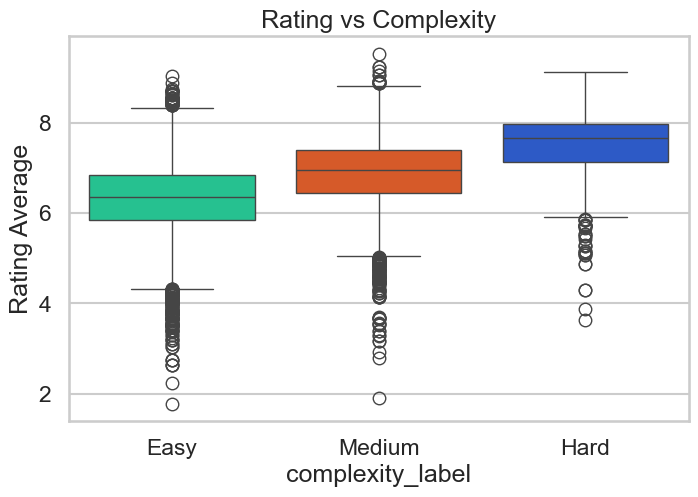

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_16248\747035733.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='game_type', data=bgg_final, palette=["#eb0a0a", "#1886f5"])


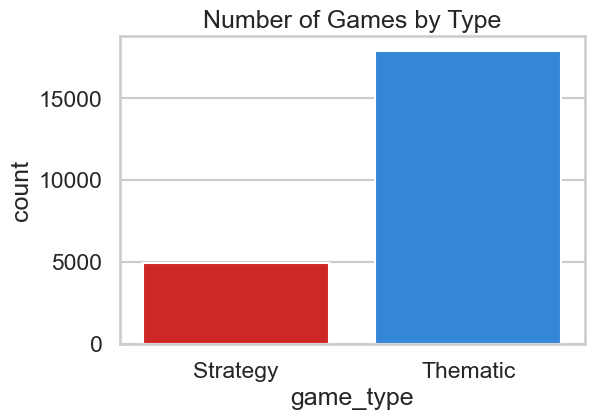

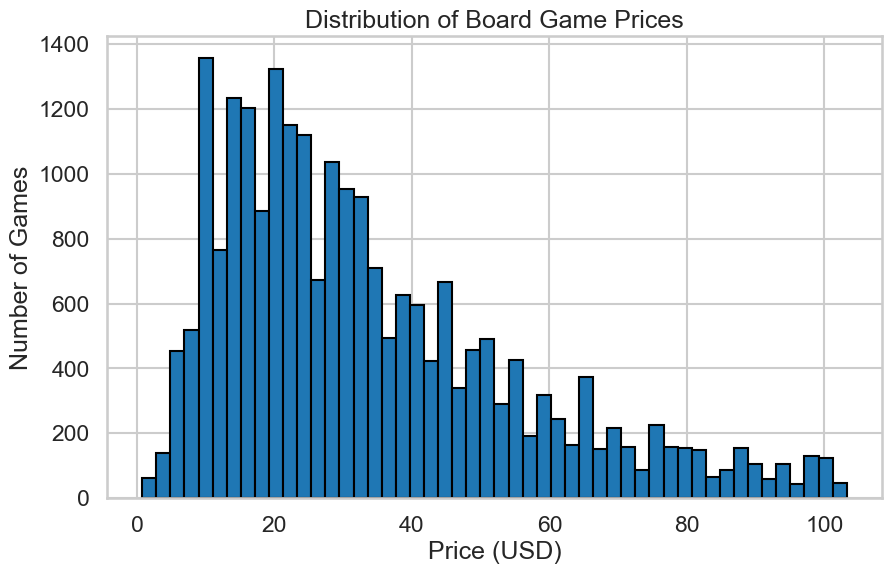

In [23]:

# Rating vs Complexity
plt.figure(figsize=(8,5))
sns.boxplot(x='complexity_label', y='Rating Average', data=bgg_final,palette=["#0cdb99", "#f34d0c", "#1350e0"])
plt.title("Rating vs Complexity")
plt.show()

# Count of game types
plt.figure(figsize=(6,4))
sns.countplot(x='game_type', data=bgg_final, palette=["#eb0a0a", "#1886f5"])
plt.title("Number of Games by Type")
plt.show()

# Price distribution
plt.figure(figsize=(10,6))
plt.hist(bgg_final['price'].dropna(), bins=50, edgecolor='black')
plt.title('Distribution of Board Game Prices')
plt.xlabel('Price (USD)')
plt.ylabel('Number of Games')
plt.show()

### Mechanics Associated with more successful game

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_16248\4095497505.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


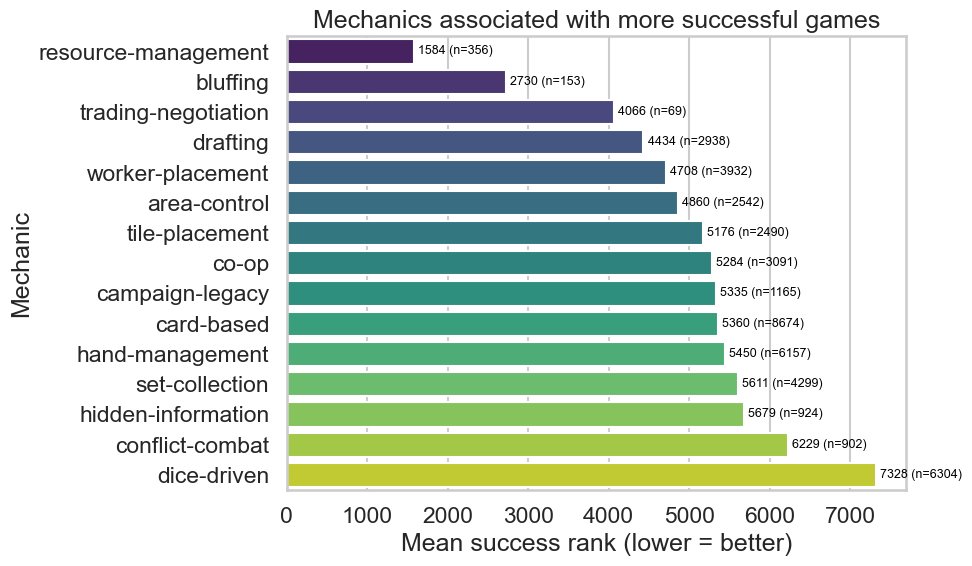

In [21]:
mech_exploded = (
    bgg_final
    # just fill NaN lists with empty lists; no split
    .assign(Mechanics_annotated=bgg_final['Mechanics_annotated'].apply(
        lambda x: x if isinstance(x, list) else []
    ))
    .explode('Mechanics_annotated')
)

# now Mechanics_annotated contains single mechanic strings
mech_exploded['Mechanics_annotated'] = mech_exploded['Mechanics_annotated'].astype(str).str.strip()
mech_exploded = mech_exploded[mech_exploded['Mechanics_annotated'] != ""]

mech_summary = (
    mech_exploded
    .groupby('Mechanics_annotated', as_index=False)
    .agg(mean_rank=('Success Rank', 'mean'),
         count=('Success Rank', 'size'))
    .dropna(subset=['mean_rank'])
    .sort_values('mean_rank')
)

mech_summary.head(15)

# Visualize
import seaborn as sns
import matplotlib.pyplot as plt

# pick mechanics with enough games and best average rank
plot_df = mech_summary.query('count >= 50').nsmallest(15, 'mean_rank')

sns.set_style("whitegrid")
sns.set_context("talk")  # slightly larger fonts

plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=plot_df,
    y='Mechanics_annotated',
    x='mean_rank',
    palette='viridis'   # or 'mako', 'crest', etc.
)

plt.xlabel('Mean success rank (lower = better)')
plt.ylabel('Mechanic')
plt.title('Mechanics associated with more successful games')

# add value labels: mean rank and count
for i, row in plot_df.iterrows():
    ax.text(
        row['mean_rank'] + 50,  # a bit to the right of the bar
        ax.get_yticks()[list(plot_df.index).index(i)],
        f"{row['mean_rank']:.0f} (n={row['count']})",
        va='center',
        fontsize=9,
        color='black'
    )

plt.tight_layout()
plt.show()
